In [1]:
%pip install pandas numpy matplotlib yfinance fredapi pandas-datareader pathlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
#ΕΡΩΤΗΜΑ 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from fredapi import Fred
import pandas_datareader as web
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Define FRED series
fred_series = [
    "FEDFUNDS",
    "CPIAUCSL",
    "UNRATE",
    "DGS10",
    "DGS2",
    "VIXCLS"
]

# Download raw FRED data
fred_raw = web.DataReader(
    fred_series,
    "fred",
    start="2005-01-01"
)

# Create data directories
data_folder = Path("data")
raw_folder = data_folder / "raw"

raw_folder.mkdir(parents=True, exist_ok=True)

# Save raw FRED data
fred_raw.to_csv(raw_folder / "fred_raw.csv")

print("FRED raw data downloaded successfully!")

FRED raw data downloaded successfully!


C:\Users\brent\AppData\Local\Temp\ipykernel_9904\907099511.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  fred_raw = web.DataReader(


In [4]:
# Define Yahoo Finance tickers
tickers = [
    "SPY",
    "QQQ",
    "IWM",
    "AAPL",
    "NVDA",
    "TLT",
    "GLD"
]

# Download raw daily data
yahoo_raw = yf.download(
    tickers,
    start="2005-01-01",
    auto_adjust=True
)

# Save raw Yahoo Finance data
yahoo_raw.to_csv(raw_folder / "yahoo_raw.csv")

print("Yahoo Finance raw data downloaded successfully!")

[*********************100%***********************]  7 of 7 completed


Yahoo Finance raw data downloaded successfully!


In [5]:
#ΕΡΩΤΗΜΑ 2
#Check Data types
print("FRED DATA TYPES:")
print(fred_raw.dtypes)

print("\nYAHOO FINANCE DATA TYPES:")
print(yahoo_raw.dtypes)

FRED DATA TYPES:
FEDFUNDS    float64
CPIAUCSL    float64
UNRATE      float64
DGS10       float64
DGS2        float64
VIXCLS      float64
dtype: object

YAHOO FINANCE DATA TYPES:
Price   Ticker
Close   AAPL      float64
        GLD       float64
        IWM       float64
        NVDA      float64
        QQQ       float64
        SPY       float64
        TLT       float64
High    AAPL      float64
        GLD       float64
        IWM       float64
        NVDA      float64
        QQQ       float64
        SPY       float64
        TLT       float64
Low     AAPL      float64
        GLD       float64
        IWM       float64
        NVDA      float64
        QQQ       float64
        SPY       float64
        TLT       float64
Open    AAPL      float64
        GLD       float64
        IWM       float64
        NVDA      float64
        QQQ       float64
        SPY       float64
        TLT       float64
Volume  AAPL        int64
        GLD         int64
        IWM         int64
 

In [6]:
#Missing values
print("FRED MISSING VALUES:")
print(fred_raw.isnull().sum())

print("\nYAHOO FINANCE MISSING VALUES:")
print(yahoo_raw.isnull().sum())

FRED MISSING VALUES:
FEDFUNDS    5525
CPIAUCSL    5526
UNRATE      5526
DGS10        309
DGS2         309
VIXCLS       245
dtype: int64

YAHOO FINANCE MISSING VALUES:
Price   Ticker
Close   AAPL      0
        GLD       0
        IWM       0
        NVDA      0
        QQQ       0
        SPY       0
        TLT       0
High    AAPL      0
        GLD       0
        IWM       0
        NVDA      0
        QQQ       0
        SPY       0
        TLT       0
Low     AAPL      0
        GLD       0
        IWM       0
        NVDA      0
        QQQ       0
        SPY       0
        TLT       0
Open    AAPL      0
        GLD       0
        IWM       0
        NVDA      0
        QQQ       0
        SPY       0
        TLT       0
Volume  AAPL      0
        GLD       0
        IWM       0
        NVDA      0
        QQQ       0
        SPY       0
        TLT       0
dtype: int64


In [7]:
#Duplicate dates and duplicate rows
print("FRED DUPLICATE DATES:")
print(fred_raw.index.duplicated().sum())

print("\nYAHOO DUPLICATE DATES:")
print(yahoo_raw.index.duplicated().sum())

print("\nFRED DUPLICATE ROWS:")
print(fred_raw.duplicated().sum())

print("\nYAHOO DUPLICATE ROWS:")
print(yahoo_raw.duplicated().sum())

FRED DUPLICATE DATES:
0

YAHOO DUPLICATE DATES:
0

FRED DUPLICATE ROWS:
148

YAHOO DUPLICATE ROWS:
0


In [8]:
#Outliers
def detect_outliers(df):
    numeric_data = df.select_dtypes(include=np.number)

    Q1 = numeric_data.quantile(0.25)
    Q3 = numeric_data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (numeric_data < lower_bound) |
        (numeric_data > upper_bound)
    )

    return outliers.sum()


print("FRED OUTLIERS:")
print(detect_outliers(fred_raw))

print("\nYAHOO FINANCE OUTLIERS:")
print(detect_outliers(yahoo_raw))

FRED OUTLIERS:
FEDFUNDS      0
CPIAUCSL      0
UNRATE        2
DGS10         0
DGS2          0
VIXCLS      261
dtype: int64

YAHOO FINANCE OUTLIERS:
Price   Ticker
Close   AAPL       83
        GLD       457
        IWM         0
        NVDA      880
        QQQ       145
        SPY        57
        TLT         0
High    AAPL       82
        GLD       457
        IWM         0
        NVDA      880
        QQQ       145
        SPY        50
        TLT         1
Low     AAPL       87
        GLD       457
        IWM         0
        NVDA      880
        QQQ       146
        SPY        62
        TLT         0
Open    AAPL       82
        GLD       457
        IWM         0
        NVDA      880
        QQQ       147
        SPY        58
        TLT         1
Volume  AAPL      243
        GLD       294
        IWM       303
        NVDA      198
        QQQ       306
        SPY       351
        TLT       505
dtype: int64


In [9]:
# Compare available dates
fred_dates = set(fred_raw.index)
yahoo_dates = set(yahoo_raw.index)

common_dates = fred_dates.intersection(yahoo_dates)

fred_only = fred_dates - yahoo_dates
yahoo_only = yahoo_dates - fred_dates

print("FRED observations:", len(fred_dates))
print("Yahoo observations:", len(yahoo_dates))
print("Common dates:", len(common_dates))
print("Dates only in FRED:", len(fred_only))
print("Dates only in Yahoo:", len(yahoo_only))

FRED observations: 5787
Yahoo observations: 5510
Common dates: 5509
Dates only in FRED: 278
Dates only in Yahoo: 1


In [10]:
#ΕΡΩΤΗΜΑ 3
# Convert FRED data to monthly frequency
fred_monthly = fred_raw.resample("ME").last()

# Extract adjusted closing prices from Yahoo Finance
yahoo_close = yahoo_raw["Close"]

# Convert Yahoo Finance data to monthly frequency
yahoo_monthly = yahoo_close.resample("ME").last()

# Remove the last line because of insufficient data for the current month
fred_monthly = fred_monthly.iloc[:-1]
yahoo_monthly = yahoo_monthly.iloc[:-1]

In [11]:
# Synchronize FRED and Yahoo Finance data
combined_monthly = pd.concat(
    [fred_monthly, yahoo_monthly],
    axis=1,
    join="inner"
)

# Sort observations chronologically
combined_monthly = combined_monthly.sort_index()

In [12]:
# Check final dataset
print("Final dataset information:")
combined_monthly.info()

print("\nMissing values:")
print(combined_monthly.isnull().sum())

print("\nDate range:")
print("Start:", combined_monthly.index.min())
print("End:", combined_monthly.index.max())

print("\nNumber of observations:", len(combined_monthly))

# Save synchronized dataset
combined_monthly.to_csv(
    data_folder / "combined_monthly.csv"
)

print("\nCombined dataset saved successfully!")

Final dataset information:
<class 'pandas.DataFrame'>
DatetimeIndex: 262 entries, 2005-01-31 to 2026-10-31
Freq: ME
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   FEDFUNDS  262 non-null    float64
 1   CPIAUCSL  261 non-null    float64
 2   UNRATE    261 non-null    float64
 3   DGS10     262 non-null    float64
 4   DGS2      262 non-null    float64
 5   VIXCLS    262 non-null    float64
 6   AAPL      262 non-null    float64
 7   GLD       262 non-null    float64
 8   IWM       262 non-null    float64
 9   NVDA      262 non-null    float64
 10  QQQ       262 non-null    float64
 11  SPY       262 non-null    float64
 12  TLT       262 non-null    float64
dtypes: float64(13)
memory usage: 28.7 KB

Missing values:
FEDFUNDS    0
CPIAUCSL    1
UNRATE      1
DGS10       0
DGS2        0
VIXCLS      0
AAPL        0
GLD         0
IWM         0
NVDA        0
QQQ         0
SPY         0
TLT         0
dtype: int64

Date range:

In [13]:
# Show the one date with the missing data
print(combined_monthly[combined_monthly.isnull().any(axis=1)])

            FEDFUNDS  CPIAUCSL  UNRATE  DGS10  DGS2  VIXCLS        AAPL  \
2025-10-31      4.09       NaN     NaN   4.11   3.6   17.44  269.170441   

                   GLD         IWM        NVDA         QQQ         SPY  \
2025-10-31  368.119995  243.753479  202.006042  626.128113  674.780029   

                  TLT  
2025-10-31  85.925858  


In [14]:
#ΕΡΩΤΗΜΑ 4
# Define the assets
tickers = ["SPY", "QQQ", "IWM", "AAPL", "NVDA", "TLT", "GLD"]

# Calculate monthly returns
asset_returns = combined_monthly[tickers].pct_change(fill_method=None)

# Rename return columns
asset_returns.columns = [f"{ticker}_Return" for ticker in tickers]

# Add returns to the original dataset
combined_monthly_with_returns = pd.concat(
    [combined_monthly, asset_returns],
    axis=1
)

# Display the updated dataset
print(asset_returns.dropna().head().map(lambda x: f"{x:.2%}"))

           SPY_Return QQQ_Return IWM_Return AAPL_Return NVDA_Return  \
2005-02-28      2.09%     -0.48%      1.64%      16.67%      26.48%   
2005-03-31     -1.83%     -1.75%     -2.83%      -7.11%     -18.04%   
2005-04-30     -1.87%     -4.35%     -5.66%     -13.46%      -7.70%   
2005-05-31      3.22%      8.86%      6.46%      10.26%      23.57%   
2005-06-30      0.15%     -3.32%      4.08%      -7.42%      -1.40%   

           TLT_Return GLD_Return  
2005-02-28     -1.47%      3.10%  
2005-03-31     -0.45%     -1.63%  
2005-04-30      3.87%      1.24%  
2005-05-31      3.14%     -3.92%  
2005-06-30      2.16%      4.30%  


In [15]:
# 1. Calculate 12-month annualized rolling volatility
rolling_vol = asset_returns.rolling(window=12).std() * np.sqrt(12)

# 2. Rename rolling volatility columns
rolling_vol.columns = [f"{ticker}_RollVol_12M" for ticker in tickers]

# 3. Combine prices, returns, and rolling volatility into one dataset
combined_monthly_full = pd.concat(
    [combined_monthly_with_returns, rolling_vol],
    axis=1
)

# 4. Save the updated dataset to the data folder
combined_monthly_full.to_csv(
    data_folder / "combined_monthly_full.csv"
)

# 5. Display the first 5 valid observations formatted as percentages
print("12-Month Annualized Rolling Volatility:")
print(rolling_vol.dropna().head().map(lambda x: f"{x:.2%}"))

12-Month Annualized Rolling Volatility:
           SPY_RollVol_12M QQQ_RollVol_12M IWM_RollVol_12M AAPL_RollVol_12M  \
2006-01-31           8.14%          15.40%          16.25%           35.96%   
2006-02-28           8.02%          15.67%          16.29%           37.13%   
2006-03-31           7.57%          15.42%          15.94%           37.58%   
2006-04-30           6.90%          14.29%          13.77%           33.07%   
2006-05-31           7.71%          14.45%          15.25%           38.84%   

           NVDA_RollVol_12M TLT_RollVol_12M GLD_RollVol_12M  
2006-01-31           47.12%           9.54%          14.35%  
2006-02-28           41.83%           9.36%          14.79%  
2006-03-31           36.66%          10.65%          14.22%  
2006-04-30           33.21%          10.20%          16.90%  
2006-05-31           41.01%           9.47%          15.81%  


In [16]:
# Calculate the running maximum price of each asset
running_max = combined_monthly[tickers].cummax()

# Calculate the drawdown of each asset
drawdown = (combined_monthly[tickers] / running_max) - 1

# Calculate the maximum drawdown for each asset
max_drawdown = drawdown.min()

# Display the results
print("Maximum Drawdown for each asset:")
print(max_drawdown)

Maximum Drawdown for each asset:
SPY    -0.507848
QQQ    -0.497398
IWM    -0.524728
AAPL   -0.569114
NVDA   -0.793874
TLT    -0.476137
GLD    -0.429102
dtype: float64


In [17]:
 #Define the confidence level
confidence_level = 0.95

# Calculate the historical Value at Risk for each asset
var_95 = asset_returns.quantile(1 - confidence_level)

# Display the results
print("Monthly Historical VaR (95% confidence level):")
print(var_95)

Monthly Historical VaR (95% confidence level):
SPY_Return    -0.069421
QQQ_Return    -0.075862
IWM_Return    -0.085775
AAPL_Return   -0.114702
NVDA_Return   -0.185349
TLT_Return    -0.054632
GLD_Return    -0.066210
Name: 0.050000000000000044, dtype: float64


In [18]:
#ΕΡΩΤΗΜΑ 5
#Feature 1: Inflation Rate
combined_monthly_full['inflation_rate']=combined_monthly_full['CPIAUCSL'].pct_change(periods=12)*100
print(combined_monthly_full['inflation_rate'].dropna().head(5))

2006-01-31    4.018789
2006-02-28    3.638254
2006-03-31    3.417918
2006-04-30    3.613836
2006-05-31    3.977273
Name: inflation_rate, dtype: float64


In [19]:
#Feature 2: Unemployment Change
combined_monthly_full['unemployment_change']=combined_monthly_full['UNRATE'].diff()
print(combined_monthly_full['unemployment_change'].head(5))

2005-01-31    NaN
2005-02-28    0.1
2005-03-31   -0.2
2005-04-30    0.0
2005-05-31   -0.1
Freq: ME, Name: unemployment_change, dtype: float64


In [20]:
#Feature 3: Yield Curve Slope
combined_monthly_full['yield_curve_slope']=combined_monthly_full['DGS10']-combined_monthly_full['DGS2']
print(combined_monthly_full['yield_curve_slope'].head(5))

2005-01-31    0.85
2005-02-28    0.77
2005-03-31    0.70
2005-04-30    0.55
2005-05-31    0.40
Freq: ME, Name: yield_curve_slope, dtype: float64


In [21]:
#Feature 4: VIX Change 
combined_monthly_full['vix_change']=combined_monthly_full['VIXCLS'].diff()
print(combined_monthly_full['vix_change'].head(5))

2005-01-31     NaN
2005-02-28   -0.74
2005-03-31    1.94
2005-04-30    1.29
2005-05-31   -2.02
Freq: ME, Name: vix_change, dtype: float64


In [22]:
#ΕΡΩΤΗΜΑ 6
#List of asset yields and the features that were created
a=["SPY_Return",
    "QQQ_Return",
    "IWM_Return",
    "AAPL_Return",
    "NVDA_Return",
    "TLT_Return",
    "GLD_Return", 
    "inflation_rate",
    "unemployment_change",
    "yield_curve_slope",
    "vix_change"
    ]

#Calculation of statistical measures
descriptive_stats= combined_monthly_full[a].describe()

#Results
print("Descriptive Statistics")
print(descriptive_stats)

#Correlation calculation
Correlation_stats= combined_monthly_full[a].corr()

#Results
print("Correlation")
print(Correlation_stats)

#Analysis Time
t=12

#Calculation of rolling correlation between SPY and VIX change
rolling_corr= combined_monthly_full['SPY'].rolling(t).corr(combined_monthly_full['vix_change'])

#Results
print(rolling_corr)

Descriptive Statistics
       SPY_Return  QQQ_Return  IWM_Return  AAPL_Return  NVDA_Return  \
count  261.000000  261.000000  261.000000   261.000000   261.000000   
mean     0.009580    0.013271    0.008532     0.025964     0.036262   
std      0.042686    0.053103    0.057175     0.087686     0.134447   
min     -0.165187   -0.155763   -0.214771    -0.329558    -0.388889   
25%     -0.013344   -0.017762   -0.024045    -0.031372    -0.042394   
50%      0.014738    0.017168    0.013951     0.028987     0.033601   
75%      0.035457    0.048321    0.044751     0.085082     0.118007   
max      0.126984    0.156901    0.182442     0.237701     0.553247   

       TLT_Return  GLD_Return  inflation_rate  unemployment_change  \
count  261.000000  261.000000      248.000000           259.000000   
mean     0.003059    0.009444        2.580092            -0.005019   
std      0.039415    0.050126        1.899252             0.704865   
min     -0.130708   -0.161397       -1.958761            

In [23]:
#ΕΡΩΤΗΜΑ 7
# Economic definition:
# Target_t = 1 if asset return in month (t+1) is below -5% (-0.05), otherwise 0.

threshold = -0.05  # Significant negative return threshold (-5%)
horizon = 1        # Forecast horizon: 1 month ahead

# Create binary target for each asset
for ticker in tickers:
    ret_col = f"{ticker}_Return"
    target_col = f"{ticker}_Target"
    
    # Shift return backward by 1 month so features at month t predict return at t+1
    next_month_return = combined_monthly_full[ret_col].shift(-horizon)
    
    # Assign 1 if next_month_return < threshold, 0 otherwise, preserving NaN at the end
    combined_monthly_full[target_col] = np.where(
        next_month_return.isna(),
        np.nan,
        (next_month_return < threshold).astype(int)
    )

# Check class distribution across assets
target_cols = [f"{ticker}_Target" for ticker in tickers]

print(f"Share of months with return below {threshold:.0%} (Class 1):")
for col in target_cols:
    valid_targets = combined_monthly_full[col].dropna()
    count_ones = int(valid_targets.sum())
    total_obs = len(valid_targets)
    pct_ones = valid_targets.mean()
    print(f"{col:<13}: {count_ones:>2} / {total_obs} months ({pct_ones:.2%})")

# Verify temporal alignment for SPY
print("\nAlignment check (SPY_Return_t vs SPY_Target_t covering t+1):")
check_df = combined_monthly_full[["SPY_Return", "SPY_Target"]].copy()
check_df["Next_Month_SPY_Return"] = check_df["SPY_Return"].shift(-1)
print(check_df.dropna().head(6))

Share of months with return below -5% (Class 1):
SPY_Target   : 24 / 261 months (9.20%)
QQQ_Target   : 34 / 261 months (13.03%)
IWM_Target   : 41 / 261 months (15.71%)
AAPL_Target  : 53 / 261 months (20.31%)
NVDA_Target  : 59 / 261 months (22.61%)
TLT_Target   : 19 / 261 months (7.28%)
GLD_Target   : 29 / 261 months (11.11%)

Alignment check (SPY_Return_t vs SPY_Target_t covering t+1):
            SPY_Return  SPY_Target  Next_Month_SPY_Return
2005-02-28    0.020903         0.0              -0.018293
2005-03-31   -0.018293         0.0              -0.018735
2005-04-30   -0.018735         0.0               0.032225
2005-05-31    0.032225         0.0               0.001515
2005-06-30    0.001515         0.0               0.038261
2005-07-31    0.038261         0.0              -0.009374


In [24]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [25]:
#ΕΡΩΤΗΜΑ 8
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define macroeconomic and financial feature columns
feature_cols = [
    "inflation_rate",
    "unemployment_change",
    "yield_curve_slope",
    "vix_change"
]

# Define chronological split date (train on past, test on recent period without shuffling)
split_date = "2020-01-01"

# Define benchmark and two alternative classification models
models = {
    "Benchmark_Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic_Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random_Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    )
}

print("Models initialized:", list(models.keys()))
print("Features used:", feature_cols)
print("Chronological split date:", split_date)

Models initialized: ['Benchmark_Dummy', 'Logistic_Regression', 'Random_Forest']
Features used: ['inflation_rate', 'unemployment_change', 'yield_curve_slope', 'vix_change']
Chronological split date: 2020-01-01


In [26]:
#List of assets
assets= a[:-4]
assets


['SPY_Return',
 'QQQ_Return',
 'IWM_Return',
 'AAPL_Return',
 'NVDA_Return',
 'TLT_Return',
 'GLD_Return']

In [27]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score 

In [28]:
#ΕΡΩΤΗΜΑ 9
#Loop over each asset in the assets list
for asset in assets:
    #Define the target column created in cell [23]
    base_asset= asset.replace("_Return", "")
    target_col= f"{base_asset}_Target"

    #Keep features and target for the current asset, dropping (NaN)
    data_asset= combined_monthly_full[feature_cols + [target_col]].dropna()

    #Chronological train/test split 
    train_df= data_asset[data_asset.index < split_date]
    test_df= data_asset[data_asset.index >= split_date]

    #Define feature matrices (X) and target vectors (Y) for train and test sets
    X_train, Y_train= train_df[feature_cols], train_df[target_col].astype(int)
    X_test, Y_test= test_df[feature_cols], test_df[target_col].astype(int)

    #Fit and evaluate each model on the current asset 
    for model_name in models:
        #Clone the model so each asset/model starts fresh
        classifier= clone(models[model_name])

        #Train the model on the training set
        classifier.fit(X_train, Y_train)

        #Predict on the test set and print accuracy
        y_prediction= classifier.predict(X_test)
        accuracy= accuracy_score(Y_test, y_prediction)
        print(f"{asset}| {model_name} -> Accuracy: {accuracy:.4f}")

SPY_Return| Benchmark_Dummy -> Accuracy: 0.8987
SPY_Return| Logistic_Regression -> Accuracy: 0.8481
SPY_Return| Random_Forest -> Accuracy: 0.8987
QQQ_Return| Benchmark_Dummy -> Accuracy: 0.8228
QQQ_Return| Logistic_Regression -> Accuracy: 0.7722
QQQ_Return| Random_Forest -> Accuracy: 0.8228
IWM_Return| Benchmark_Dummy -> Accuracy: 0.8101
IWM_Return| Logistic_Regression -> Accuracy: 0.7848
IWM_Return| Random_Forest -> Accuracy: 0.8101
AAPL_Return| Benchmark_Dummy -> Accuracy: 0.7595
AAPL_Return| Logistic_Regression -> Accuracy: 0.7089
AAPL_Return| Random_Forest -> Accuracy: 0.7595
NVDA_Return| Benchmark_Dummy -> Accuracy: 0.7848
NVDA_Return| Logistic_Regression -> Accuracy: 0.7342
NVDA_Return| Random_Forest -> Accuracy: 0.7215
TLT_Return| Benchmark_Dummy -> Accuracy: 0.8354
TLT_Return| Logistic_Regression -> Accuracy: 0.8228
TLT_Return| Random_Forest -> Accuracy: 0.8354
GLD_Return| Benchmark_Dummy -> Accuracy: 0.8987
GLD_Return| Logistic_Regression -> Accuracy: 0.8987
GLD_Return| Random

In [29]:
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score) 

In [30]:
#ΕΡΩΤΗΜΑ 10
#List for results for each asset-model combination
results=[]
for asset in assets:
        #Define the asset column
        base_asset= asset.replace("_Return", "")
        target_col= f"{base_asset}_Target"
        #Keep features and target for the current asset dropping (NaN)
        data_asset= combined_monthly_full[feature_cols + [target_col]].dropna()

        #Chronological train/test split
        train_df= data_asset[data_asset.index < split_date]
        test_df= data_asset[data_asset.index >= split_date]

        #Define feature matrices (X) and target vectors (Y) for train and test sets
        X_train, Y_train= train_df[feature_cols], train_df[target_col].astype(int)
        X_test, Y_test= test_df[feature_cols], test_df[target_col].astype(int)

        #Fit and evaluate each model on the current asset
        for model_name in models:
            #Clone the model so asset/model starts fresh
            classifier= clone(models[model_name])

            #Train the model on the training set
            classifier.fit(X_train, Y_train)

            #Checking whether the model supports probabilities
            probabilities= hasattr(classifier, "predict_probabilities")

            #Out of sample metrics
            Y_test_prediction= classifier.predict(X_test)
            out_accuracy= accuracy_score(Y_test, Y_test_prediction)
            out_precision= precision_score(Y_test, Y_test_prediction, zero_division=0)
            out_recall= recall_score(Y_test, Y_test_prediction, zero_division=0)
            out_f1= f1_score(Y_test, Y_test_prediction, zero_division=0)

            #Calculation out of sample ROC-AUC
            if hasattr(classifier, "predict_proba") and len(np.unique(Y_test))>1:
                out_auc= roc_auc_score(Y_test, classifier.predict_proba(X_test)[:, 1])
            else: 
                out_auc= float("NaN")

            #In sample fit
            Y_train_prediction= classifier.predict(X_train)
            in_accuracy= accuracy_score(Y_train, Y_train_prediction)
            in_precision= precision_score(Y_train, Y_train_prediction, zero_division=0)
            in_recall= recall_score(Y_train, Y_train_prediction, zero_division=0)
            in_f1= f1_score(Y_train, Y_train_prediction, zero_division=0)

            #Calculation in sample ROC-AUC
            if hasattr(classifier, "predict_proba") and len (np.unique(Y_train))>1:
                in_auc= roc_auc_score(Y_train, classifier.predict_proba(X_train)[:, 1])
            else:
                in_auc= float("NaN")

            results.append({
                "Asset": asset,
                "Model": model_name,
                "Out_accuracy": round(out_accuracy, 3),
                "Out_precision": round(out_precision, 3),
                "Out_recall": round(out_recall, 3),
                "Out_f1": round(out_f1, 3),
                "Out_auc": round(out_auc, 3) if pd.notna(out_auc) else None,
                "In_accuracy": round(in_accuracy, 3),
                "In_precision": round(in_precision, 3),
                "In_recall": round(in_recall, 3 ),
                "In_f1": round(in_f1, 3),
                "In_auc": round(in_auc, 3) if pd.notna(in_auc) else None, })
            
                
            
    

In [31]:
#Create DataFrame and display consolidated results table
results_df= pd.DataFrame(results)
display(results_df)

,Asset,Model,Out_accuracy,Out_precision,Out_recall,Out_f1,Out_auc,In_accuracy,In_precision,In_recall,In_f1,In_auc
0,SPY_Return,Benchmark_Dummy,0.899,0.000,0.000,0.000,0.500,0.905,0.000,0.000,0.000,0.500
1,SPY_Return,Logistic_Regression,0.848,0.000,0.000,0.000,0.768,0.917,1.000,0.125,0.222,0.721
2,SPY_Return,Random_Forest,0.899,0.000,0.000,0.000,0.752,0.911,1.000,0.062,0.118,0.961
3,QQQ_Return,Benchmark_Dummy,0.823,0.000,0.000,0.000,0.500,0.881,0.000,0.000,0.000,0.500
4,QQQ_Return,Logistic_Regression,0.772,0.167,0.071,0.100,0.699,0.893,1.000,0.100,0.182,0.657
5,QQQ_Return,Random_Forest,0.823,0.000,0.000,0.000,0.618,0.887,1.000,0.050,0.095,0.918
6,IWM_Return,Benchmark_Dummy,0.810,0.000,0.000,0.000,0.500,0.851,0.000,0.000,0.000,0.500
7,IWM_Return,Logistic_Regression,0.785,0.000,0.000,0.000,0.596,0.857,1.000,0.040,0.077,0.652
8,IWM_Return,Random_Forest,0.810,0.000,0.000,0.000,0.582,0.863,1.000,0.080,0.148,0.909
9,AAPL_Return,Benchmark_Dummy,0.759,0.000,0.000,0.000,0.500,0.815,0.000,0.000,0.000,0.500


,Asset,Model,Feature,Importance_Mean,Importance_Std
0,SPY_Return,Logistic_Regression,inflation_rate,0.2633,0.0591
1,SPY_Return,Logistic_Regression,unemployment_change,0.0877,0.0690
2,SPY_Return,Logistic_Regression,yield_curve_slope,0.0253,0.0192
3,SPY_Return,Logistic_Regression,vix_change,0.0711,0.0434
4,SPY_Return,Random_Forest,inflation_rate,0.1164,0.0720
...,...,...,...,...,...
79,GLD_Return,Random_Forest,vix_change,-0.0302,0.0557
80,GLD_Return,Benchmark_Dummy,inflation_rate,0.0000,0.0000
81,GLD_Return,Benchmark_Dummy,unemployment_change,0.0000,0.0000
82,GLD_Return,Benchmark_Dummy,yield_curve_slope,0.0000,0.0000



Average contribution (ROC-AUC drop) per feature across all assets:


Model,Logistic_Regression,Random_Forest,Benchmark_Dummy
Feature,,,
inflation_rate,0.1208,0.0840,0.0
unemployment_change,0.0213,-0.0052,0.0
vix_change,0.0208,0.0167,0.0
yield_curve_slope,0.0188,-0.0015,0.0


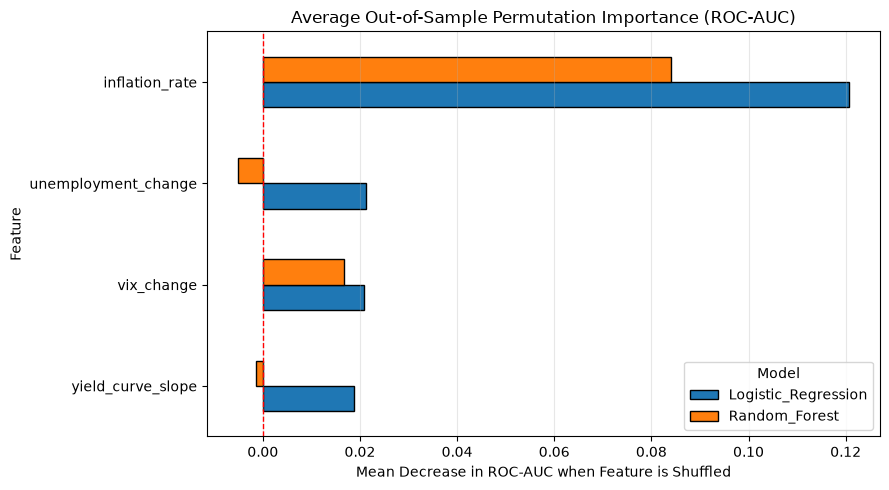

ROBUSTNESS CHECK 1: ALTERNATIVE THRESHOLD (-10%)


,Asset,Model,Alternative_Threshold,Test_Positives,Accuracy,Precision,Recall,F1,ROC_AUC
0,SPY_Return,Benchmark_Dummy,-0.1,1,0.987,0.000,0.0,0.000,0.500
1,SPY_Return,Logistic_Regression,-0.1,1,0.962,0.000,0.0,0.000,0.974
2,SPY_Return,Random_Forest,-0.1,1,0.987,0.000,0.0,0.000,0.628
3,QQQ_Return,Benchmark_Dummy,-0.1,2,0.975,0.000,0.0,0.000,0.500
4,QQQ_Return,Logistic_Regression,-0.1,2,0.899,0.125,0.5,0.200,0.877
5,QQQ_Return,Random_Forest,-0.1,2,0.975,0.000,0.0,0.000,0.812
6,IWM_Return,Benchmark_Dummy,-0.1,1,0.987,0.000,0.0,0.000,0.500
7,IWM_Return,Logistic_Regression,-0.1,1,0.962,0.000,0.0,0.000,0.974
8,IWM_Return,Random_Forest,-0.1,1,0.987,0.000,0.0,0.000,0.936
9,AAPL_Return,Benchmark_Dummy,-0.1,4,0.949,0.000,0.0,0.000,0.500



ROBUSTNESS CHECK 2: SUB-SAMPLE ANALYSIS


,Sub-sample,Asset,Model,Test_Positives,Accuracy,Precision,Recall,F1,ROC_AUC
0,2005-2014,SPY_Return,Benchmark_Dummy,1,0.970,0.0,0.0,0.0,0.500
1,2005-2014,SPY_Return,Logistic_Regression,1,0.970,0.0,0.0,0.0,0.844
2,2005-2014,SPY_Return,Random_Forest,1,0.970,0.0,0.0,0.0,0.125
3,2005-2014,QQQ_Return,Benchmark_Dummy,2,0.939,0.0,0.0,0.0,0.500
4,2005-2014,QQQ_Return,Logistic_Regression,2,0.939,0.0,0.0,0.0,0.419
...,...,...,...,...,...,...,...,...,...
58,2020-onwards,TLT_Return,Logistic_Regression,3,0.875,0.0,0.0,0.0,0.413
59,2020-onwards,TLT_Return,Random_Forest,3,0.875,0.0,0.0,0.0,0.635
60,2020-onwards,GLD_Return,Benchmark_Dummy,4,0.833,0.0,0.0,0.0,0.500
61,2020-onwards,GLD_Return,Logistic_Regression,4,0.833,0.0,0.0,0.0,0.425


In [32]:
#ΕΡΩΤΗΜΑ 11
from sklearn. inspection import permutation_importance

# Permutation Importance analysis
importance_results=[]

# Select models to evaluate 
eval_models = ["Logistic_Regression", "Random_Forest","Benchmark_Dummy"]

for asset in assets:
    # Define target column
    base_asset = asset.replace("_Return", "")
    target_col = f"{base_asset}_Target"

    # Keep features and target, dropping missing values (NaN)
    data_asset = combined_monthly_full[feature_cols + [target_col]].dropna()

    # Chronological train / test split
    train_df = data_asset[data_asset.index < split_date]
    test_df = data_asset[data_asset.index >= split_date]

    X_train, Y_train = train_df[feature_cols], train_df[target_col].astype(int)
    X_test, Y_test = test_df[feature_cols], test_df[target_col].astype(int)

    # Skip the asset if train or test contains only one class (ROC-AUC is undefined)
    if Y_train.nunique() < 2 or Y_test.nunique() < 2:
        print(f"Skipping {asset}: only one class in train or test set")
        continue

    # Loop over all models including Benchmark_Dummy
    for model_name in eval_models:
        classifier = clone(models[model_name])
        classifier.fit(X_train, Y_train)

        # Compute Out-of-Sample Permutation Importance on test set using ROC-AUC
        perm_importance = permutation_importance(
            classifier,
            X_test,
            Y_test,
            scoring="roc_auc",
            n_repeats=30,
            random_state=42
        )

        for i, feature in enumerate(feature_cols):
            importance_results.append({
                "Asset": asset,
                "Model": model_name,
                "Feature": feature,
                "Importance_Mean": perm_importance.importances_mean[i],
                "Importance_Std": perm_importance.importances_std[i]
            })

# Create consolidated results DataFrame
importance_df = pd.DataFrame(importance_results)
display(importance_df.round(4))

# Summary table: Average importance per feature and model across all assets
summary_importance = (
    importance_df.groupby(["Model", "Feature"])["Importance_Mean"]
    .mean()
    .unstack(level=0)
    .reindex(columns=eval_models)
    .sort_values(by="Logistic_Regression", ascending=False)
)

print("\nAverage contribution (ROC-AUC drop) per feature across all assets:")
display(summary_importance.round(4))

# Visualization
# Benchmark_Dummy is excluded from the plot (its importance is always 0)
# ascending=True so that the most important feature appears at the top of the barh plot
plot_data = (
    summary_importance
    .drop(columns="Benchmark_Dummy")
    .sort_values(by="Logistic_Regression", ascending=True)
)

plot_data.plot(kind="barh", figsize=(9, 5), edgecolor="black")
plt.axvline(0, color="red", linestyle="--", linewidth=1)
plt.title("Average Out-of-Sample Permutation Importance (ROC-AUC)")
plt.xlabel("Mean Decrease in ROC-AUC when Feature is Shuffled")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#ΕΡΩΤΗΜΑ 12
# ROBUSTNESS CHECK 1: ALTERNATIVE MEASURES

# Define an alternative variable
alternative_threshold= -0.10

h=1

# Create alternative target variables 
for asset in assets:
    base_asset = asset.replace("_Return", "")
    ret_col = f"{base_asset}_Return"
    alt_target = f"{base_asset}_Target_Alt"
    
    next_month = combined_monthly_full[ret_col].shift(-h)
    
    combined_monthly_full[alt_target] = np.where(
        next_month.isna(),
        np.nan,
        (next_month < alternative_threshold).astype(int)
    )

# Store alternative results
alternative_results = []

# Loop over each asset
for asset in assets:
    base_asset = asset.replace("_Return", "")
    target_col = f"{base_asset}_Target_Alt"
    data_asset = combined_monthly_full[feature_cols + [target_col]].dropna()

    # Chronological train/test split
    train_df = data_asset[data_asset.index < split_date]
    test_df = data_asset[data_asset.index >= split_date]

    X_train, y_train = train_df[feature_cols], train_df[target_col].astype(int)
    X_test, y_test = test_df[feature_cols], test_df[target_col].astype(int)

    # Skip the asset if the training data contains only one class
    if y_train.nunique() < 2:
        print(f"Skipping {asset} (Alt Threshold): only one class in training data")
        continue

    # Evaluate each model
    for model_name, model in models.items():
        classifier = clone(model)
        classifier.fit(X_train, y_train)
        y_pred = classifier.predict(X_test)

        # Calculate ROC-AUC if probabilities are supported and test set has both classes
        if hasattr(classifier, "predict_proba") and y_test.nunique() > 1:
            out_auc = roc_auc_score(y_test, classifier.predict_proba(X_test)[:, 1])
        else:
            out_auc = np.nan

        alternative_results.append({
            "Asset": asset,
            "Model": model_name,
            "Alternative_Threshold": alternative_threshold,
            "Test_Positives": int(y_test.sum()),
            "Accuracy": round(accuracy_score(y_test, y_pred), 3),
            "Precision": round(precision_score(y_test, y_pred, zero_division=0), 3),
            "Recall": round(recall_score(y_test, y_pred, zero_division=0), 3),
            "F1": round(f1_score(y_test, y_pred, zero_division=0), 3),
            "ROC_AUC": round(out_auc, 3) if pd.notna(out_auc) else None
        })

# Create and display results DataFrame
alternative_results_df = pd.DataFrame(alternative_results)
print("ROBUSTNESS CHECK 1: ALTERNATIVE THRESHOLD (-10%)")
display(alternative_results_df)

#ROBUSTNESS CHECK 2: SUB-SAMPLE ANALYSIS

#Define the three test periods
periods = {
    "2005-2014": ("2005-01-01", "2015-01-01"),
    "2015-2019": ("2015-01-01", "2020-01-01"),
    "2020-onwards": ("2020-01-01", None)
}

#List to store results
periods_results = []

# Loop over each time period
for period_name, (start_date, end_date) in periods.items():
    # Loop over each asset
    for asset in assets:
        base_asset = asset.replace("_Return", "")
        target_col = f"{base_asset}_Target"

        # Keep features and target, remove missing values
        data_asset = combined_monthly_full[feature_cols + [target_col]].dropna()

        # Filter observations for the current sub-period
        period_data = data_asset[data_asset.index >= start_date]
        if end_date is not None:
            period_data = period_data[period_data.index < end_date]

        # Check if there are enough observations
        if len(period_data) < 20:
            print(f"Skipping {asset} in {period_name}: not enough observations ({len(period_data)})")
            continue

        # Chronological 70/30 train/test split within the sub-period
        split_point = int(len(period_data) * 0.70)
        train_df = period_data.iloc[:split_point]
        test_df = period_data.iloc[split_point:]

        X_train, Y_train = train_df[feature_cols], train_df[target_col].astype(int)
        X_test, Y_test = test_df[feature_cols], test_df[target_col].astype(int)

        # Check if training data contains both classes
        if Y_train.nunique() < 2:
            print(f"Skipping {asset} in {period_name}: only one class in training data")
            continue

        # Loop over each model
        for model_name, model in models.items():
            classifier = clone(model)
            classifier.fit(X_train, Y_train)
            Y_prediction = classifier.predict(X_test)

            # Calculate ROC-AUC if applicable
            if hasattr(classifier, "predict_proba") and Y_test.nunique() > 1:
                out_auc = roc_auc_score(Y_test, classifier.predict_proba(X_test)[:, 1])
            else:
                out_auc = np.nan

            periods_results.append({
                "Sub-sample": period_name,
                "Asset": asset,
                "Model": model_name,
                "Test_Positives": int(Y_test.sum()),
                "Accuracy": round(accuracy_score(Y_test, Y_prediction), 3),
                "Precision": round(precision_score(Y_test, Y_prediction, zero_division=0), 3),
                "Recall": round(recall_score(Y_test, Y_prediction, zero_division=0), 3),
                "F1": round(f1_score(Y_test, Y_prediction, zero_division=0), 3),
                "ROC_AUC": round(out_auc, 3) if pd.notna(out_auc) else None
            })

# Create and display final results table
periods_results_df = pd.DataFrame(periods_results)
print("\nROBUSTNESS CHECK 2: SUB-SAMPLE ANALYSIS")
display(periods_results_df)









